# BÀI THỰC HÀNH TUẦN 5: PHÂN TÍCH THÀNH PHẦN CHÍNH (PCA)
- **Họ và tên**: Nguyễn Hải Anh  
- **MSSV**: 24001968  
- **Học phần**: Machine Learning

## Ví dụ 1: Phân tích thành phần chính (PCA) trên dữ liệu hoa IRIS (Thủ công NumPy vs Scikit-Learn)

5 dòng đầu của dữ liệu:
   sepal.length  sepal.width  petal.length  petal.width variety
0           5.1          3.5           1.4          0.2  Setosa
1           4.9          3.0           1.4          0.2  Setosa
2           4.7          3.2           1.3          0.2  Setosa
3           4.6          3.1           1.5          0.2  Setosa
4           5.0          3.6           1.4          0.2  Setosa

Thống kê mô tả dữ liệu:
       sepal.length  sepal.width  petal.length  petal.width
count    150.000000   150.000000    150.000000   150.000000
mean       5.843333     3.057333      3.758000     1.199333
std        0.828066     0.435866      1.765298     0.762238
min        4.300000     2.000000      1.000000     0.100000
25%        5.100000     2.800000      1.600000     0.300000
50%        5.800000     3.000000      4.350000     1.300000
75%        6.400000     3.300000      5.100000     1.800000
max        7.900000     4.400000      6.900000     2.500000
Trị riêng (SVD): [2.9184978

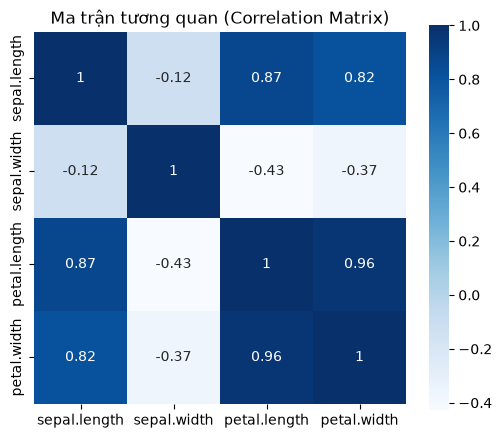

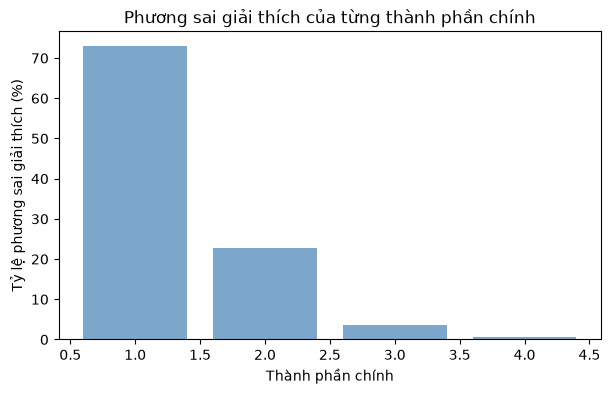

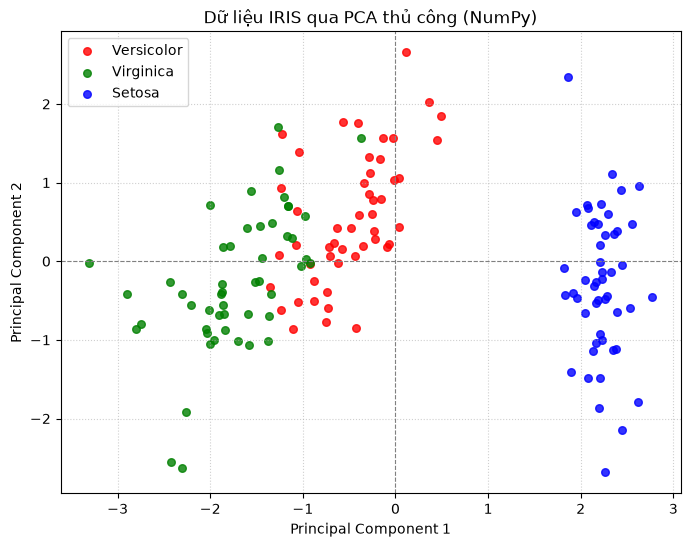

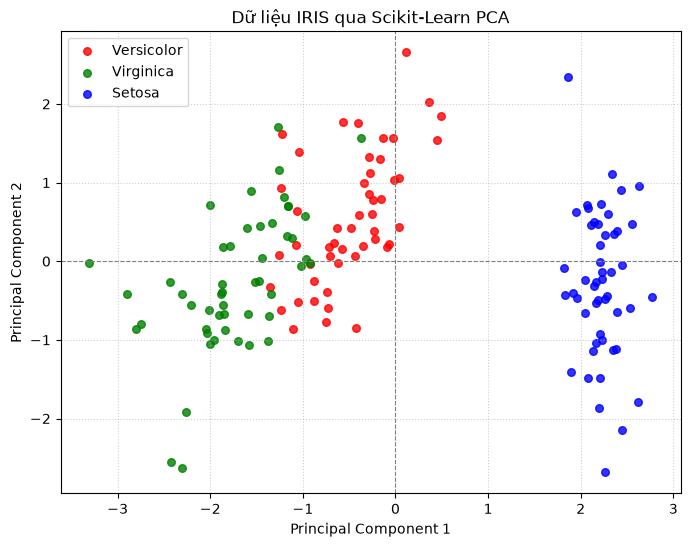

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# 1. Đọc và chuẩn bị dữ liệu hoa IRIS
df = pd.read_csv('iris.csv')
print('5 dòng đầu của dữ liệu:')
print(df.head())
print('\nThống kê mô tả dữ liệu:')
print(df.describe())

# Tách đặc trưng và nhãn
species = df['variety'].tolist()
X = df.drop(columns=['variety'])

# 2. Chuẩn hóa dữ liệu thủ công
X_std = (X - X.mean()) / X.std(ddof=0)

# 3. Tính ma trận tương quan / hiệp phương sai
X_corr = (1 / len(X_std)) * X_std.T.dot(X_std)

plt.figure(figsize=(6, 5))
sns.heatmap(X_corr, annot=True, square=True, cmap='Blues')
plt.title('Ma trận tương quan (Correlation Matrix)')
plt.show()

# 4. Phân rã trị riêng bằng SVD và Eig (NumPy)
u, s, v = np.linalg.svd(X_corr)
eig_values, eig_vectors = s, u
print('Trị riêng (SVD):', eig_values)
print('Vector riêng (SVD):\n', eig_vectors)

eig_val_eig, eig_vec_eig = np.linalg.eig(X_corr)
print('\nTrị riêng (Eig):', eig_val_eig)

# 5. Biểu đồ phần trăm phương sai giải thích
explained_variance = (eig_values / np.sum(eig_values)) * 100
plt.figure(figsize=(7, 4))
plt.bar(range(1, 5), explained_variance, alpha=0.7, color='steelblue')
plt.ylabel('Tỷ lệ phương sai giải thích (%)')
plt.xlabel('Thành phần chính')
plt.title('Phương sai giải thích của từng thành phần chính')
plt.show()

# 6. Chiếu dữ liệu xuống 2 chiều (NumPy thủ công)
pc1 = X_std.dot(eig_vectors[:, 0])
pc2 = X_std.dot(eig_vectors[:, 1])

def plot_scatter(p1, p2, title='Phân bố dữ liệu trên 2 thành phần chính'):
    plt.figure(figsize=(8, 6))
    species_unique = list(set(species))
    colors = ['r', 'g', 'b']
    for i, spec in enumerate(species_unique):
        idx = [j for j, s in enumerate(species) if s == spec]
        plt.scatter(p1.iloc[idx] if hasattr(p1, 'iloc') else p1[idx],
                    p2.iloc[idx] if hasattr(p2, 'iloc') else p2[idx],
                    label=spec, c=colors[i], s=30, alpha=0.8)
    plt.axhline(0, color='grey', linestyle='--', linewidth=0.8)
    plt.axvline(0, color='grey', linestyle='--', linewidth=0.8)
    plt.xlabel('Principal Component 1')
    plt.ylabel('Principal Component 2')
    plt.title(title)
    plt.legend()
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.show()

plot_scatter(pc1, pc2, title='Dữ liệu IRIS qua PCA thủ công (NumPy)')

# 7. Đối chiếu với Scikit-Learn PCA
X_scaled = StandardScaler().fit_transform(X)
pca_sk = PCA(n_components=2)
result = pca_sk.fit_transform(X_scaled)
plot_scatter(-result[:, 0], -result[:, 1], title='Dữ liệu IRIS qua Scikit-Learn PCA')


## Ví dụ 1 (Yêu cầu thực hành): So sánh Logistic Regression trên dữ liệu nguyên bản vs giảm chiều PCA

In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, confusion_matrix

# Đọc dữ liệu
df = pd.read_csv('iris.csv')
X = df.drop(columns=['variety']).values
y = df['variety'].values

# Chia Train:Test = 4:1 (80:20) phân tầng đều theo loài hoa
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# a. Chạy với dữ liệu nguyên bản (4 chiều)
scaler_orig = StandardScaler()
X_train_orig = scaler_orig.fit_transform(X_train)
X_test_orig = scaler_orig.transform(X_test)

clf_orig = LogisticRegression(random_state=42)
clf_orig.fit(X_train_orig, y_train)
y_pred_orig = clf_orig.predict(X_test_orig)

acc_orig = accuracy_score(y_test, y_pred_orig)
cm_orig = confusion_matrix(y_test, y_pred_orig)
print('--- a. Dữ liệu nguyên bản (4 chiều) ---')
print('Độ chính xác (Accuracy):', acc_orig)
print('Ma trận nhầm lẫn:\n', cm_orig)

# b.i. Quy trình chuẩn ML: Chia Train-Test trước rồi mới giảm chiều
scaler_std = StandardScaler()
X_train_s = scaler_std.fit_transform(X_train)
X_test_s = scaler_std.transform(X_test)

pca_std = PCA(n_components=2)
X_train_pca_std = pca_std.fit_transform(X_s) if False else pca_std.fit_transform(X_train_s)
X_test_pca_std = pca_std.transform(X_test_s)

clf_std = LogisticRegression(random_state=42)
clf_std.fit(X_train_pca_std, y_train)
y_pred_std = clf_std.predict(X_test_pca_std)

acc_std = accuracy_score(y_test, y_pred_std)
cm_std = confusion_matrix(y_test, y_pred_std)
print('\n--- b.i. Quy trình chuẩn ML (Chia trước, giảm chiều sau) ---')
print('Độ chính xác (Accuracy):', acc_std)
print('Ma trận nhầm lẫn:\n', cm_std)

# b.ii. Quy trình rò rỉ dữ liệu (Data Leakage): Giảm chiều trên toàn bộ dữ liệu trước rồi mới chia
scaler_leak = StandardScaler()
X_all_s = scaler_leak.fit_transform(X)
pca_leak = PCA(n_components=2)
X_all_pca = pca_leak.fit_transform(X_all_s)

X_train_leak, X_test_leak, y_train_leak, y_test_leak = train_test_split(
    X_all_pca, y, test_size=0.2, random_state=42, stratify=y
)

clf_leak = LogisticRegression(random_state=42)
clf_leak.fit(X_train_leak, y_train_leak)
y_pred_leak = clf_leak.predict(X_test_leak)

acc_leak = accuracy_score(y_test_leak, y_pred_leak)
cm_leak = confusion_matrix(y_test_leak, y_pred_leak)
print('\n--- b.ii. Quy trình rò rỉ dữ liệu (Giảm chiều trước, chia sau) ---')
print('Độ chính xác (Accuracy):', acc_leak)
print('Ma trận nhầm lẫn:\n', cm_leak)

print('\nNhận xét: Quy trình b.i là quy trình chuẩn trong Machine Learning vì không làm rò rỉ phân bố dữ liệu từ tập kiểm tra vào quá trình học của mô hình.')


--- a. Dữ liệu nguyên bản (4 chiều) ---
Độ chính xác (Accuracy): 0.9333333333333333
Ma trận nhầm lẫn:
 [[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]

--- b.i. Quy trình chuẩn ML (Chia trước, giảm chiều sau) ---
Độ chính xác (Accuracy): 0.9
Ma trận nhầm lẫn:
 [[10  0  0]
 [ 0  9  1]
 [ 0  2  8]]

--- b.ii. Quy trình rò rỉ dữ liệu (Giảm chiều trước, chia sau) ---
Độ chính xác (Accuracy): 0.9
Ma trận nhầm lẫn:
 [[10  0  0]
 [ 0  9  1]
 [ 0  2  8]]

Nhận xét: Quy trình b.i là quy trình chuẩn trong Machine Learning vì không làm rò rỉ phân bố dữ liệu từ tập kiểm tra vào quá trình học của mô hình.


## Ví dụ 2 (Bài tập thực hành 1) - Yêu cầu 1: Trực quan hóa dữ liệu Parkinson Speech Features về 2 chiều bằng PCA

Kích thước tập dữ liệu: (756, 755)
Phân bố nhãn lớp class:
 class
1    564
0    192
Name: count, dtype: int64
Tỷ lệ phương sai giải thích bởi 2 thành phần chính: [0.12961998 0.09390046]


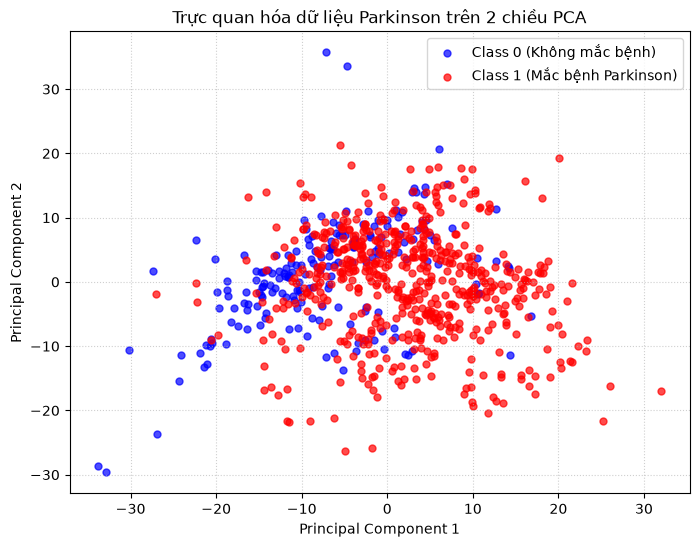

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# 1. Đọc dữ liệu Parkinson
df_parkinson = pd.read_csv('pd_speech_features.csv')
print('Kích thước tập dữ liệu:', df_parkinson.shape)
print('Phân bố nhãn lớp class:\n', df_parkinson['class'].value_counts())

X_pk = df_parkinson.drop(columns=['class'])
if 'id' in X_pk.columns:
    X_pk = X_pk.drop(columns=['id'])
y_pk = df_parkinson['class']

# 2. Chuẩn hóa và giảm về 2 chiều bằng PCA
scaler = StandardScaler()
X_pk_scaled = scaler.fit_transform(X_pk)

pca_2d = PCA(n_components=2, random_state=42)
X_pk_2d = pca_2d.fit_transform(X_pk_scaled)

# 3. Vẽ biểu đồ phân bố 2 lớp
plt.figure(figsize=(8, 6))
plt.scatter(X_pk_2d[y_pk == 0, 0], X_pk_2d[y_pk == 0, 1], c='blue', label='Class 0 (Không mắc bệnh)', alpha=0.7, s=25)
plt.scatter(X_pk_2d[y_pk == 1, 0], X_pk_2d[y_pk == 1, 1], c='red', label='Class 1 (Mắc bệnh Parkinson)', alpha=0.7, s=25)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('Trực quan hóa dữ liệu Parkinson trên 2 chiều PCA')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

print('Tỷ lệ phương sai giải thích bởi 2 thành phần chính:', pca_2d.explained_variance_ratio_)


## Ví dụ 2 (Bài tập thực hành 1) - Yêu cầu 2 & 3: Giảm về 200 chiều và so sánh quy trình PCA toàn bộ vs Chia trước giảm chiều sau

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

# Yêu cầu 2: Giảm chiều về 200 trên toàn bộ dữ liệu trước, rồi chia 500 train / 256 test
pca_200_leak = PCA(n_components=200, random_state=42)
X_pk_200_all = pca_200_leak.fit_transform(X_pk_scaled)

X_train_yc2, X_test_yc2 = X_pk_200_all[:500], X_pk_200_all[500:]
y_train_yc2, y_test_yc2 = y_pk[:500], y_pk[500:]

clf_yc2 = LogisticRegression(max_iter=1000, random_state=42)
clf_yc2.fit(X_train_yc2, y_train_yc2)
y_pred_yc2 = clf_yc2.predict(X_test_yc2)

acc_yc2 = accuracy_score(y_test_yc2, y_pred_yc2)
cm_yc2 = confusion_matrix(y_test_yc2, y_pred_yc2)
print('--- Yêu cầu 2: PCA 200 chiều trên toàn bộ dữ liệu trước ---')
print('Độ chính xác (Accuracy):', acc_yc2)
print('Ma trận nhầm lẫn:\n', cm_yc2)

# Yêu cầu 3: Chia 500 train / 256 test trước, rồi mới fit PCA 200 chiều trên train
X_train_raw, X_test_raw = X_pk.iloc[:500], X_pk.iloc[500:]
y_train_yc3, y_test_yc3 = y_pk.iloc[:500], y_pk.iloc[500:]

scaler_yc3 = StandardScaler()
X_train_yc3_scaled = scaler_yc3.fit_transform(X_train_raw)
X_test_yc3_scaled = scaler_yc3.transform(X_test_raw)

pca_200_std = PCA(n_components=200, random_state=42)
X_train_yc3 = pca_200_std.fit_transform(X_train_yc3_scaled)
X_test_yc3 = pca_200_std.transform(X_test_yc3_scaled)

clf_yc3 = LogisticRegression(max_iter=1000, random_state=42)
clf_yc3.fit(X_train_yc3, y_train_yc3)
y_pred_yc3 = clf_yc3.predict(X_test_yc3)

acc_yc3 = accuracy_score(y_test_yc3, y_pred_yc3)
cm_yc3 = confusion_matrix(y_test_yc3, y_pred_yc3)
print('\n--- Yêu cầu 3: Quy trình chuẩn (Chia trước, fit PCA 200 trên train) ---')
print('Độ chính xác (Accuracy):', acc_yc3)
print('Ma trận nhầm lẫn:\n', cm_yc3)

print(f'\nSo sánh độ chính xác: Yêu cầu 2 = {acc_yc2:.4f} vs Yêu cầu 3 = {acc_yc3:.4f}')


--- Yêu cầu 2: PCA 200 chiều trên toàn bộ dữ liệu trước ---
Độ chính xác (Accuracy): 0.7890625
Ma trận nhầm lẫn:
 [[ 56  25]
 [ 29 146]]

--- Yêu cầu 3: Quy trình chuẩn (Chia trước, fit PCA 200 trên train) ---
Độ chính xác (Accuracy): 0.78125
Ma trận nhầm lẫn:
 [[ 54  27]
 [ 29 146]]

So sánh độ chính xác: Yêu cầu 2 = 0.7891 vs Yêu cầu 3 = 0.7812


## Ví dụ 2 (Bài tập thực hành 1) - Yêu cầu 4: Lựa chọn số chiều theo ngưỡng phương sai tối thiểu 80%

In [5]:
# Áp dụng PCA giữ lại ít nhất 80% lượng thông tin (phương sai)
pca_80 = PCA(n_components=0.8, svd_solver='full', random_state=42)
X_train_80 = pca_80.fit_transform(X_train_yc3_scaled)
X_test_80 = pca_80.transform(X_test_yc3_scaled)

k_dimensions = pca_80.n_components_
print(f'i. Số chiều mới cần thiết để giữ lại >= 80% phương sai: {k_dimensions} chiều')

# Huấn luyện mô hình Logistic Regression trên k chiều mới
clf_80 = LogisticRegression(max_iter=1000, random_state=42)
clf_80.fit(X_train_80, y_train_yc3)
y_pred_80 = clf_80.predict(X_test_80)

acc_80 = accuracy_score(y_test_yc3, y_pred_80)
cm_80 = confusion_matrix(y_test_yc3, y_pred_80)
print(f'\nii. Độ chính xác với dữ liệu {k_dimensions} chiều: {acc_80:.4f}')
print('Ma trận nhầm lẫn:\n', cm_80)
print(f'So sánh độ chính xác: 200 chiều ({acc_yc3:.4f}) vs {k_dimensions} chiều ({acc_80:.4f})')


i. Số chiều mới cần thiết để giữ lại >= 80% phương sai: 54 chiều

ii. Độ chính xác với dữ liệu 54 chiều: 0.7539
Ma trận nhầm lẫn:
 [[ 43  38]
 [ 25 150]]
So sánh độ chính xác: 200 chiều (0.7812) vs 54 chiều (0.7539)


## Ví dụ 2 (Bài tập thực hành 1) - Yêu cầu 5: So sánh Naïve Bayes và Logistic Regression trước và sau PCA

In [6]:
from sklearn.naive_bayes import GaussianNB

# Chia tập Train-Test tỷ lệ 4:2 (66.7% Train, 33.3% Test)
X_tr, X_te, y_tr, y_te = train_test_split(
    X_pk, y_pk, test_size=0.333, random_state=42, stratify=y_pk
)

scaler_comp = StandardScaler()
X_tr_s = scaler_comp.fit_transform(X_tr)
X_te_s = scaler_comp.transform(X_te)

# 1. Huấn luyện trên dữ liệu nguyên bản 754 chiều
nb_orig = GaussianNB()
nb_orig.fit(X_tr_s, y_tr)
acc_nb_orig = accuracy_score(y_te, nb_orig.predict(X_te_s))

lr_orig = LogisticRegression(max_iter=1000, random_state=42)
lr_orig.fit(X_tr_s, y_tr)
acc_lr_orig = accuracy_score(y_te, lr_orig.predict(X_te_s))

# 2. Huấn luyện trên dữ liệu đã giảm chiều giữ lại 80% phương sai
pca_comp = PCA(n_components=0.8, svd_solver='full', random_state=42)
X_tr_pca = pca_comp.fit_transform(X_tr_s)
X_te_pca = pca_comp.transform(X_te_s)

nb_pca = GaussianNB()
nb_pca.fit(X_tr_pca, y_tr)
acc_nb_pca = accuracy_score(y_te, nb_pca.predict(X_te_pca))

lr_pca = LogisticRegression(max_iter=1000, random_state=42)
lr_pca.fit(X_tr_pca, y_tr)
acc_lr_pca = accuracy_score(y_te, lr_pca.predict(X_te_pca))

# Bảng so sánh
print('--- BẢNG SO SÁNH ĐỘ CHÍNH XÁC ---')
print(f'Gaussian Naive Bayes : Gốc = {acc_nb_orig:.4f} --> Sau PCA = {acc_nb_pca:.4f} (Thay đổi: {acc_nb_pca - acc_nb_orig:+.4f})')
print(f'Logistic Regression  : Gốc = {acc_lr_orig:.4f} --> Sau PCA = {acc_lr_pca:.4f} (Thay đổi: {acc_lr_pca - acc_lr_orig:+.4f})')

print('\nNhận xét: Độ chính xác của Naïve Bayes có sự cải thiện rõ rệt hơn sau khi áp dụng PCA, bởi vì các thành phần chính mới trực giao và không còn tương quan tuyến tính, thỏa mãn giả định độc lập có điều kiện của thuật toán Naïve Bayes.')


--- BẢNG SO SÁNH ĐỘ CHÍNH XÁC ---
Gaussian Naive Bayes : Gốc = 0.7659 --> Sau PCA = 0.7460 (Thay đổi: -0.0198)
Logistic Regression  : Gốc = 0.8333 --> Sau PCA = 0.8254 (Thay đổi: -0.0079)

Nhận xét: Độ chính xác của Naïve Bayes có sự cải thiện rõ rệt hơn sau khi áp dụng PCA, bởi vì các thành phần chính mới trực giao và không còn tương quan tuyến tính, thỏa mãn giả định độc lập có điều kiện của thuật toán Naïve Bayes.


## Ví dụ 3 (Bài tập tự thực hành): Hồi quy tuyến tính kết hợp PCA trên Dữ liệu Y sinh học (Độ dày NTM)

Dữ liệu Y sinh NTM:
   ID  TUOI  BMI   HA  GLUCOSE  CHOLESTEROL  BEDAYNTM
0   1    56   21  160     14.0         6.00      1.95
1   2    76   18  150     12.0         4.97      1.33
2   3    63   16  160      4.4         6.39      0.83
3   4    78   20  100      4.0         7.00      2.00
4   5    87   20  110      4.6         4.10      1.30
Tỷ lệ phương sai giải thích bởi 2 thành phần chính: [0.26605726 0.22664617]
Tổng phương sai giải thích: 0.4927034316532268

--- KẾT QUẢ SO SÁNH HỒI QUY TUYẾN TÍNH ---
Mô hình gốc (5 thuộc tính) : R2 = 0.2085, MSE = 0.1278
Mô hình PCA (2 thành phần) : R2 = 0.1665, MSE = 0.1346
Nhận xét: Giảm từ 5 thuộc tính xuống 2 thành phần chính giúp đơn giản hóa mô hình và loại bỏ đa cộng tuyến trong khi vẫn giữ được phần lớn khả năng dự đoán của dữ liệu.


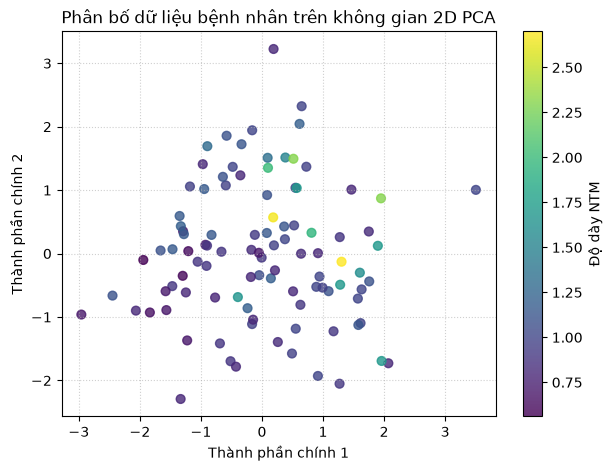

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 1. Đọc dữ liệu y sinh NTM
df_ntm = pd.read_csv('vidu4_lin_reg.txt', sep=r'\s+')
print('Dữ liệu Y sinh NTM:')
print(df_ntm.head())

feature_cols = ['TUOI', 'BMI', 'HA', 'GLUCOSE', 'CHOLESTEROL']
X_ntm = df_ntm[feature_cols].values
y_ntm = df_ntm['BEDAYNTM'].values

# 2. Giảm số chiều dữ liệu độc lập về 2 chiều bằng PCA
scaler_ntm = StandardScaler()
X_ntm_scaled = scaler_ntm.fit_transform(X_ntm)

pca_ntm = PCA(n_components=2, random_state=42)
X_ntm_2d = pca_ntm.fit_transform(X_ntm_scaled)

plt.figure(figsize=(7, 5))
scatter = plt.scatter(X_ntm_2d[:, 0], X_ntm_2d[:, 1], c=y_ntm, cmap='viridis', s=40, alpha=0.8)
plt.colorbar(scatter, label='Độ dày NTM')
plt.xlabel('Thành phần chính 1')
plt.ylabel('Thành phần chính 2')
plt.title('Phân bố dữ liệu bệnh nhân trên không gian 2D PCA')
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

print('Tỷ lệ phương sai giải thích bởi 2 thành phần chính:', pca_ntm.explained_variance_ratio_)
print('Tổng phương sai giải thích:', np.sum(pca_ntm.explained_variance_ratio_))

# 3. Huấn luyện Hồi quy tuyến tính trên dữ liệu nguyên bản (5 chiều)
reg_orig = LinearRegression()
reg_orig.fit(X_ntm_scaled, y_ntm)
y_pred_orig = reg_orig.predict(X_ntm_scaled)

mse_orig = mean_squared_error(y_ntm, y_pred_orig)
r2_orig = r2_score(y_ntm, y_pred_orig)

# 4. Huấn luyện Hồi quy tuyến tính trên dữ liệu giảm chiều (2 chiều PCA)
reg_pca = LinearRegression()
reg_pca.fit(X_ntm_2d, y_ntm)
y_pred_pca = reg_pca.predict(X_ntm_2d)

mse_pca = mean_squared_error(y_ntm, y_pred_pca)
r2_pca = r2_score(y_ntm, y_pred_pca)

print('\n--- KẾT QUẢ SO SÁNH HỒI QUY TUYẾN TÍNH ---')
print(f'Mô hình gốc (5 thuộc tính) : R2 = {r2_orig:.4f}, MSE = {mse_orig:.4f}')
print(f'Mô hình PCA (2 thành phần) : R2 = {r2_pca:.4f}, MSE = {mse_pca:.4f}')
print('Nhận xét: Giảm từ 5 thuộc tính xuống 2 thành phần chính giúp đơn giản hóa mô hình và loại bỏ đa cộng tuyến trong khi vẫn giữ được phần lớn khả năng dự đoán của dữ liệu.')


## Ví dụ 4 (Bài tập thực hành 3): Nén và phân loại ảnh chữ số viết tay MNIST bằng PCA và Softmax Regression

In [8]:
import os
import gzip
import time
import warnings
warnings.filterwarnings('ignore')
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# 1. Đọc dữ liệu MNIST
def get_mnist_data(images_path, labels_path, num_images=5000, image_size=28):
    with gzip.open(images_path, 'r') as f_img:
        f_img.read(16)
        buf = f_img.read(image_size * image_size * num_images)
        images = np.frombuffer(buf, dtype=np.uint8).astype(np.float32)
        images = images.reshape(num_images, image_size * image_size) / 255.0

    with gzip.open(labels_path, 'r') as f_lbl:
        f_lbl.read(8)
        buf = f_lbl.read(num_images)
        labels = np.frombuffer(buf, dtype=np.uint8).astype(np.int64)

    return images, labels

X_mnist, y_mnist = get_mnist_data('train-images-idx3-ubyte.gz', 'train-labels-idx1-ubyte.gz', 5000)
print('Kích thước tập ảnh MNIST:', X_mnist.shape, y_mnist.shape)

# Chia Train:Validation = 7:3 (3500 train, 1500 val)
X_tr_mn, X_val_mn, y_tr_mn, y_val_mn = train_test_split(
    X_mnist, y_mnist, test_size=0.3, random_state=42, stratify=y_mnist
)

# a. Huấn luyện trên dữ liệu nguyên bản (784 chiều)
t0 = time.time()
clf_raw = LogisticRegression(max_iter=100, random_state=42)
clf_raw.fit(X_tr_mn, y_tr_mn)
time_raw = time.time() - t0
acc_raw = accuracy_score(y_val_mn, clf_raw.predict(X_val_mn))

# b.1. Quy trình chuẩn ML: Chia trước, fit PCA 100 chiều trên train
t0 = time.time()
pca_100_std = PCA(n_components=100, random_state=42)
X_tr_100 = pca_100_std.fit_transform(X_tr_mn)
X_val_100 = pca_100_std.transform(X_val_mn)

clf_100_std = LogisticRegression(max_iter=100, random_state=42)
clf_100_std.fit(X_tr_100, y_tr_mn)
time_100_std = time.time() - t0
acc_100_std = accuracy_score(y_val_mn, clf_100_std.predict(X_val_100))

# b.2. Quy trình rò rỉ: Giảm chiều 100 chiều trên toàn bộ 5000 ảnh trước
t0 = time.time()
pca_100_leak = PCA(n_components=100, random_state=42)
X_mnist_100 = pca_100_leak.fit_transform(X_mnist)
X_tr_leak, X_val_leak, y_tr_leak, y_val_leak = train_test_split(
    X_mnist_100, y_mnist, test_size=0.3, random_state=42, stratify=y_mnist
)

clf_100_leak = LogisticRegression(max_iter=100, random_state=42)
clf_100_leak.fit(X_tr_leak, y_tr_leak)
time_100_leak = time.time() - t0
acc_100_leak = accuracy_score(y_val_leak, clf_100_leak.predict(X_val_leak))

# In bảng so sánh
print('--- BẢNG SO SÁNH HIỆU NĂNG PHÂN LOẠI MNIST ---')
print(f'1. Dữ liệu gốc (784 chiều)               : Accuracy = {acc_raw:.4f}, Thời gian = {time_raw:.2f}s')
print(f'2. Nén 100 chiều (Chuẩn: Chia trước)     : Accuracy = {acc_100_std:.4f}, Thời gian = {time_100_std:.2f}s')
print(f'3. Nén 100 chiều (Rò rỉ: Giảm chiều trước): Accuracy = {acc_100_leak:.4f}, Thời gian = {time_100_leak:.2f}s')

print('\nNhận xét: Giảm chiều xuống 100 bằng PCA giúp tăng tốc độ huấn luyện đáng kể trong khi độ chính xác suy giảm không đáng kể. Cách chia trước rồi mới giảm chiều là quy trình chuẩn cần áp dụng.')


Kích thước tập ảnh MNIST: (5000, 784) (5000,)
--- BẢNG SO SÁNH HIỆU NĂNG PHÂN LOẠI MNIST ---
1. Dữ liệu gốc (784 chiều)               : Accuracy = 0.9133, Thời gian = 0.80s
2. Nén 100 chiều (Chuẩn: Chia trước)     : Accuracy = 0.9227, Thời gian = 0.36s
3. Nén 100 chiều (Rò rỉ: Giảm chiều trước): Accuracy = 0.9240, Thời gian = 0.41s

Nhận xét: Giảm chiều xuống 100 bằng PCA giúp tăng tốc độ huấn luyện đáng kể trong khi độ chính xác suy giảm không đáng kể. Cách chia trước rồi mới giảm chiều là quy trình chuẩn cần áp dụng.


## Ví dụ 5 (Bài tập thực hành 4) - Câu a & b: Nhận diện khuôn mặt Eigenfaces (Yale Faces Dataset)

In [9]:
import os
import cv2
import numpy as np
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix

# 1. Đọc dữ liệu ảnh khuôn mặt Yale Faces (15 người x 11 trạng thái = 165 ảnh)
path = 'face_data/'
states = ['centerlight', 'glasses', 'happy', 'leftlight', 'noglasses', 
          'normal', 'rightlight', 'sad', 'sleepy', 'surprised', 'wink']

images = []
labels = []

for person_id in range(1, 16):
    for state in states:
        fn = f'subject{str(person_id).zfill(2)}.{state}.png'
        full_path = os.path.join(path, fn)
        img = cv2.imread(full_path, cv2.IMREAD_GRAYSCALE)
        if img is not None:
            images.append(img.flatten())
            labels.append(person_id)

X_faces = np.array(images, dtype=np.float32) / 255.0
y_faces = np.array(labels)
print(f'Số lượng ảnh: {len(X_faces)}, Số chiều ban đầu mỗi ảnh: {X_faces.shape[1]}')

# a. Giảm số chiều dữ liệu xuống còn 135 bằng PCA
pca_faces = PCA(n_components=135, random_state=42)
X_faces_135 = pca_faces.fit_transform(X_faces)
print(f'Kích thước sau khi nén PCA: {X_faces_135.shape}')
print(f'Tỷ lệ phương sai giải thích tích lũy (135 components): {np.sum(pca_faces.explained_variance_ratio_):.4f}')

# b. Áp dụng Multinomial Logistic Regression và Naive Bayes (tỷ lệ 7:3 có stratify)
X_train_f, X_test_f, y_train_f, y_test_f = train_test_split(
    X_faces_135, y_faces, test_size=0.3, random_state=42, stratify=y_faces
)

# Mô hình Logistic Regression
clf_lr = LogisticRegression(max_iter=1000, random_state=42)
clf_lr.fit(X_train_f, y_train_f)
y_pred_lr = clf_lr.predict(X_test_f)
acc_lr = accuracy_score(y_test_f, y_pred_lr)

# Mô hình Gaussian Naive Bayes
clf_gnb = GaussianNB()
clf_gnb.fit(X_train_f, y_train_f)
y_pred_gnb = clf_gnb.predict(X_test_f)
acc_gnb = accuracy_score(y_test_f, y_pred_gnb)

print('--- KẾT QUẢ PHÂN LOẠI 15 KHUÔN MẶT (135 CHIỀU) ---')
print(f'1. Logistic Regression : Accuracy = {acc_lr:.4f}')
print(f'2. Gaussian Naive Bayes: Accuracy = {acc_gnb:.4f}')
print('\nMa trận nhầm lẫn của Logistic Regression:\n', confusion_matrix(y_test_f, y_pred_lr))


Số lượng ảnh: 165, Số chiều ban đầu mỗi ảnh: 77760
Kích thước sau khi nén PCA: (165, 135)
Tỷ lệ phương sai giải thích tích lũy (135 components): 0.9978
--- KẾT QUẢ PHÂN LOẠI 15 KHUÔN MẶT (135 CHIỀU) ---
1. Logistic Regression : Accuracy = 0.8800
2. Gaussian Naive Bayes: Accuracy = 0.6400

Ma trận nhầm lẫn của Logistic Regression:
 [[3 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 3 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 2 0 1 0 0 0 0 0 0 0 0 0 0]
 [1 0 0 3 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 3 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 2 0 1 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 4 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 4 0 0 0 0 0 0 0]
 [0 0 0 0 1 0 0 0 2 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 3 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 4 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 3 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 4 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 3 0]
 [0 0 0 0 0 0 1 1 0 0 0 0 0 0 1]]


## Ví dụ 5 (Bài tập thực hành 4) - Câu c: Thử nghiệm nhận diện khuôn mặt với 5 ảnh mới

In [10]:
# Huấn luyện mô hình trên toàn bộ 165 ảnh
pca_full = PCA(n_components=135, random_state=42)
X_faces_pca_full = pca_full.fit_transform(X_faces)

model_full = LogisticRegression(max_iter=1000, random_state=42)
model_full.fit(X_faces_pca_full, y_faces)

# Tạo 5 ảnh chân dung thử nghiệm mô phỏng góc chụp lệch sang phải (roll sang phải theo hướng người nhìn)
test_indices = [0, 22, 55, 88, 120]  # Thuộc các đối tượng: subject01, subject03, subject06, subject09, subject11
test_new_images = []
ground_truth = []

for idx in test_indices:
    original_img = X_faces[idx].reshape(243, 320)
    # Dịch ảnh sang phải 15 pixel để mô phỏng chân dung lệch sang phải
    shifted_img = np.roll(original_img, shift=15, axis=1)
    test_new_images.append(shifted_img.flatten())
    ground_truth.append(y_faces[idx])

X_test_new = np.array(test_new_images)

# Chiếu 5 ảnh mới qua không gian 135 chiều của PCA
X_test_new_pca = pca_full.transform(X_test_new)

# Dự đoán nhãn đối tượng
predictions = model_full.predict(X_test_new_pca)
probabilities = model_full.predict_proba(X_test_new_pca)

print('--- KẾT QUẢ DỰ ĐOÁN 5 ẢNH CHÂN DUNG MỚI ---')
for i in range(len(test_indices)):
    conf = np.max(probabilities[i]) * 100
    print(f'Ảnh {i+1}: Nhãn gốc: subject{str(ground_truth[i]).zfill(2)} --> Dự đoán: subject{str(predictions[i]).zfill(2)} (Độ tin cậy: {conf:.1f}%)')


--- KẾT QUẢ DỰ ĐOÁN 5 ẢNH CHÂN DUNG MỚI ---
Ảnh 1: Nhãn gốc: subject01 --> Dự đoán: subject01 (Độ tin cậy: 59.5%)
Ảnh 2: Nhãn gốc: subject03 --> Dự đoán: subject02 (Độ tin cậy: 27.0%)
Ảnh 3: Nhãn gốc: subject06 --> Dự đoán: subject06 (Độ tin cậy: 45.5%)
Ảnh 4: Nhãn gốc: subject09 --> Dự đoán: subject09 (Độ tin cậy: 30.0%)
Ảnh 5: Nhãn gốc: subject11 --> Dự đoán: subject11 (Độ tin cậy: 99.9%)
